# Modelado y evaluación

**Proyecto:** Predicción de la gravedad de siniestros viales en CABA

**Autor:** Juan Pablo Monllor - Aprendizaje Automático 2026

Esta notebook parte del dataset limpio generado en `1.0-jpm-eda-preprocesamiento.ipynb`. Separa los datos por fecha, entrena y compara modelos de clasificación, elige sus hiperparámetros con validación sobre el entrenamiento y evalúa el modelo elegido una sola vez con el conjunto de prueba.

In [1]:
# Librerías para manejar datos y hacer gráficos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import joblib

## 1. Carga de datos

In [2]:
# Cargo el dataset limpio. parse_dates convierte la fecha de texto a formato fecha.
datos = pd.read_csv("../data/processed/siniestros_limpio.csv", parse_dates=["fecha_siniestro"])

print("Filas y columnas:", datos.shape)
print("Período:", datos["fecha_siniestro"].min().date(), "a", datos["fecha_siniestro"].max().date())
datos.head()

Filas y columnas: (51144, 9)
Período: 2019-01-01 a 2025-12-31


,fecha_siniestro,modo_desplazamiento_victima,contraparte_siniestro,tipo_de_via_siniestro,hora,lluvia_mm,tipo_dia,estacion,grave_o_mortal
0,2019-01-01,AUTO,UTILITARIO,AUTOPISTA,1,0.0,FERIADO,VERANO,0
1,2019-01-01,MOTO,AUTO,AVENIDA,18,0.1,FERIADO,VERANO,1
2,2019-01-01,AUTO,AUTO,SIN DATO,13,0.0,FERIADO,VERANO,0
3,2019-01-01,AUTO,CAMION,SIN DATO,7,0.0,FERIADO,VERANO,0
4,2019-01-01,AUTO,MOVIL,SIN DATO,12,0.0,FERIADO,VERANO,0


## 2. Partición temporal

Antes de cualquier otra decisión, los datos se separan por fecha: los siniestros de 2019 a 2024 forman el conjunto de entrenamiento y los de 2025, el de prueba. Así se simula el uso real del modelo: entrenar con el pasado y predecir siniestros posteriores. El conjunto de prueba se reserva y se usa una sola vez, en la evaluación final.

In [3]:
# Ordeno por fecha y separo: entrenamiento 2019-2024, prueba 2025.
datos = datos.sort_values("fecha_siniestro").reset_index(drop=True)
es_prueba = datos["fecha_siniestro"].dt.year == 2025

entrenamiento = datos[~es_prueba]
prueba = datos[es_prueba]

for nombre, conjunto in [("Entrenamiento", entrenamiento), ("Prueba", prueba)]:
    print(f"{nombre}: {len(conjunto)} siniestros "
          f"({round(len(conjunto) / len(datos) * 100, 1)}%), "
          f"graves: {round(conjunto['grave_o_mortal'].mean() * 100, 1)}%")

Entrenamiento: 40995 siniestros (80.2%), graves: 6.7%
Prueba: 10149 siniestros (19.8%), graves: 7.4%


## 3. Predictoras y preprocesamiento

Se separan las predictoras (X) de la variable objetivo (y). La fecha no se usa como predictora.

- **Categóricas:** vehículo de la víctima, contraparte, tipo de vía, tipo de día, estación y hora. La hora se trata como categoría porque su relación con la gravedad no es lineal: el porcentaje de graves sube de madrugada, baja durante el día y vuelve a subir a la noche.
- **Numérica:** lluvia en milímetros.

Las categóricas se codifican con one-hot y la lluvia se escala. Ambas transformaciones se definen acá, pero se ajustan solo con los datos de entrenamiento, dentro de cada modelo. `handle_unknown="ignore"` permite que el modelo procese una categoría que no apareció en el entrenamiento, en lugar de dar error.

In [4]:
categoricas = ["modo_desplazamiento_victima", "contraparte_siniestro",
               "tipo_de_via_siniestro", "tipo_dia", "estacion", "hora"]
numericas = ["lluvia_mm"]

X_entrenamiento = entrenamiento[categoricas + numericas]
y_entrenamiento = entrenamiento["grave_o_mortal"]
X_prueba = prueba[categoricas + numericas]
y_prueba = prueba["grave_o_mortal"]

# Defino las transformaciones (todavía no se ajustan con ningún dato)
preprocesamiento = ColumnTransformer([
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas),
    ("numericas", StandardScaler(), numericas)
])

print("X entrenamiento:", X_entrenamiento.shape, "| X prueba:", X_prueba.shape)

X entrenamiento: (40995, 7) | X prueba: (10149, 7)


## 4. Validación y línea base

Para elegir hiperparámetros y comparar modelos sin usar el conjunto de prueba, se usa validación cruzada temporal (`TimeSeriesSplit`) sobre el entrenamiento: los datos, ordenados por fecha, se dividen en 5 tramos, y en cada vuelta el modelo se entrena con los tramos anteriores y se valida con el siguiente.

Cada modelo se arma como un pipeline (preprocesamiento + modelo), de modo que la codificación y el escalado se ajustan solo con la parte de entrenamiento de cada vuelta.

Como punto de comparación se usa una línea base que siempre predice "leve".

In [5]:
import warnings

validacion = TimeSeriesSplit(n_splits=5)
metricas = ["accuracy", "precision", "recall", "f1"]

linea_base = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("modelo", DummyClassifier(strategy="most_frequent"))
])

with warnings.catch_warnings():
    # La precisión queda indefinida porque este modelo nunca predice "grave"
    warnings.simplefilter("ignore")
    resultados = cross_validate(linea_base, X_entrenamiento, y_entrenamiento,
                                cv=validacion, scoring=metricas)

for m in metricas:
    print(f"{m}: {resultados['test_' + m].mean():.3f}")

accuracy: 0.930
precision: 0.000
recall: 0.000
f1: 0.000


**Observaciones:** la línea base obtiene una exactitud de 0,930 sin detectar ningún siniestro grave (recall 0). Esto confirma que la exactitud no sirve para evaluar este problema: los modelos se comparan por precisión, recall y F1 de la clase grave o mortal.

## 5. Regresión logística

La regresión logística estima la probabilidad de que un siniestro sea grave o mortal a partir de una combinación ponderada de las predictoras. Si esa probabilidad supera un umbral (por defecto 0,5), el siniestro se clasifica como grave.

- `class_weight="balanced"`: da más peso a los siniestros graves durante el entrenamiento, para compensar que son solo el 6,7%.
- Hiperparámetro **C**: controla la regularización. Valores chicos simplifican el modelo y valores grandes le permiten ajustarse más a los datos de entrenamiento. Se prueban 0,01, 0,1, 1 y 10 con `GridSearchCV` y la validación temporal.
- **Criterio de elección:** el F1 de la clase grave o mortal, que equilibra recall y precisión.

In [6]:
pipeline_logistica = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("modelo", LogisticRegression(class_weight="balanced", max_iter=1000))
])

grilla_logistica = {"modelo__C": [0.01, 0.1, 1, 10]}

busqueda_logistica = GridSearchCV(pipeline_logistica, grilla_logistica, cv=validacion,
                                  scoring=["precision", "recall", "f1"], refit="f1")
busqueda_logistica.fit(X_entrenamiento, y_entrenamiento)

# Resultados promedio de la validación para cada valor de C
tabla_logistica = pd.DataFrame(busqueda_logistica.cv_results_)[
    ["param_modelo__C", "mean_test_precision", "mean_test_recall", "mean_test_f1"]].round(3)
print("Mejor C:", busqueda_logistica.best_params_["modelo__C"])
tabla_logistica

Mejor C: 1


,param_modelo__C,mean_test_precision,mean_test_recall,mean_test_f1
0,0.01,0.093,0.733,0.163
1,0.10,0.096,0.730,0.168
2,1.00,0.096,0.727,0.168
3,10.00,0.096,0.725,0.168


**Observaciones:**

- Con el umbral de 0,5, la regresión logística detecta alrededor del 73% de los siniestros graves (recall), pero solo el 9,6% de sus alarmas corresponden a siniestros graves (precisión): aproximadamente 9 de cada 10 alarmas son falsas.
- El valor de C casi no modifica los resultados (F1 entre 0,163 y 0,168). Se elige C = 1, el de mejor F1 promedio en la validación.
- El balance entre detectar graves y generar falsas alarmas puede ajustarse con el umbral, que se elige más adelante con la validación.

## 6. Árbol de decisión

El árbol de decisión clasifica cada siniestro haciendo una serie de preguntas sobre las predictoras (por ejemplo, "¿la contraparte es un objeto fijo?") hasta llegar a una hoja con la predicción. No necesita escalado, pero se usa el mismo pipeline para comparar en las mismas condiciones; escalar la lluvia no cambia sus resultados.

- `class_weight="balanced"`, igual que en la regresión logística.
- Hiperparámetros: **max_depth** (cantidad máxima de preguntas seguidas) y **min_samples_leaf** (mínimo de siniestros por hoja). Limitarlos evita que el árbol memorice el entrenamiento.
- Mismo criterio de elección: F1 de la clase grave o mortal.

In [7]:
pipeline_arbol = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("modelo", DecisionTreeClassifier(class_weight="balanced", random_state=42))
])

grilla_arbol = {"modelo__max_depth": [3, 5, 8, 12],
                "modelo__min_samples_leaf": [50, 200]}

busqueda_arbol = GridSearchCV(pipeline_arbol, grilla_arbol, cv=validacion,
                              scoring=["precision", "recall", "f1"], refit="f1")
busqueda_arbol.fit(X_entrenamiento, y_entrenamiento)

tabla_arbol = pd.DataFrame(busqueda_arbol.cv_results_)[
    ["param_modelo__max_depth", "param_modelo__min_samples_leaf",
     "mean_test_precision", "mean_test_recall", "mean_test_f1"]].round(3)
print("Mejores parámetros:", busqueda_arbol.best_params_)
tabla_arbol.sort_values("mean_test_f1", ascending=False)

Mejores parámetros: {'modelo__max_depth': 8, 'modelo__min_samples_leaf': 50}


,param_modelo__max_depth,param_modelo__min_samples_leaf,mean_test_precision,mean_test_recall,mean_test_f1
4,8,50,0.097,0.663,0.167
5,8,200,0.094,0.687,0.164
6,12,50,0.095,0.685,0.164
2,5,50,0.095,0.702,0.163
7,12,200,0.091,0.718,0.160
3,5,200,0.090,0.710,0.156
0,3,50,0.080,0.787,0.146
1,3,200,0.081,0.793,0.146


**Observaciones:**

- La mejor configuración es `max_depth=8` y `min_samples_leaf=50`, con precisión 0,097, recall 0,663 y F1 0,167 en la validación.
- Los árboles más simples (profundidad 3) detectan más graves (recall cercano a 0,79), pero con menos precisión, por lo que su F1 es menor.
- El resultado es muy similar al de la regresión logística (F1 0,168), con algo menos de recall.

## 7. KNN (K vecinos más cercanos)

KNN clasifica cada siniestro según lo que ocurrió con los K siniestros más parecidos del entrenamiento. Es sensible a la escala de las variables, por eso la lluvia se escala; las categóricas ya quedan en 0 y 1 con la codificación.

- KNN no tiene una opción para compensar el desbalance como `class_weight`.
- Hiperparámetro **n_neighbors (K)**: se prueban 5, 25 y 51 vecinos.
- Mismo criterio de elección: F1 de la clase grave o mortal.

In [8]:
pipeline_knn = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("modelo", KNeighborsClassifier())
])

grilla_knn = {"modelo__n_neighbors": [5, 25, 51]}

with warnings.catch_warnings():
    # Si un K nunca predice "grave", la precisión queda indefinida
    warnings.simplefilter("ignore")
    busqueda_knn = GridSearchCV(pipeline_knn, grilla_knn, cv=validacion,
                                scoring=["precision", "recall", "f1"], refit="f1")
    busqueda_knn.fit(X_entrenamiento, y_entrenamiento)

tabla_knn = pd.DataFrame(busqueda_knn.cv_results_)[
    ["param_modelo__n_neighbors", "mean_test_precision", "mean_test_recall", "mean_test_f1"]].round(3)
print("Mejor K:", busqueda_knn.best_params_["modelo__n_neighbors"])
tabla_knn

Mejor K: 5


,param_modelo__n_neighbors,mean_test_precision,mean_test_recall,mean_test_f1
0,5,0.168,0.066,0.069
1,25,0.048,0.007,0.012
2,51,0.000,0.000,0.000


**Observaciones:**

- KNN obtiene resultados muy inferiores: con K = 5 detecta solo el 6,6% de los siniestros graves (F1 0,069), y con 25 o 51 vecinos prácticamente no detecta ninguno.
- Como los graves son pocos, entre los vecinos de casi cualquier siniestro predominan los leves, y KNN no tiene una opción para compensar el desbalance. Por eso no es adecuado para este problema tal como está planteado.

## 8. Comparación y elección del modelo

Se comparan las mejores configuraciones de cada modelo con las mismas métricas de la validación temporal (umbral 0,5). El conjunto de prueba todavía no se usa.

In [9]:
# Métricas de validación de la mejor configuración de cada modelo
comparacion = []
for nombre, busqueda in [("Regresión logística", busqueda_logistica),
                         ("Árbol de decisión", busqueda_arbol),
                         ("KNN", busqueda_knn)]:
    mejor = busqueda.best_index_
    resultados_cv = busqueda.cv_results_
    comparacion.append({
        "modelo": nombre,
        "parámetros": busqueda.best_params_,
        "precision": round(resultados_cv["mean_test_precision"][mejor], 3),
        "recall": round(resultados_cv["mean_test_recall"][mejor], 3),
        "f1": round(resultados_cv["mean_test_f1"][mejor], 3)
    })

pd.DataFrame(comparacion)

,modelo,parámetros,precision,recall,f1
0,Regresión logística,{'modelo__C': 1},0.096,0.727,0.168
1,Árbol de decisión,"{'modelo__max_depth': 8, 'modelo__min_samples_...",0.097,0.663,0.167
2,KNN,{'modelo__n_neighbors': 5},0.168,0.066,0.069


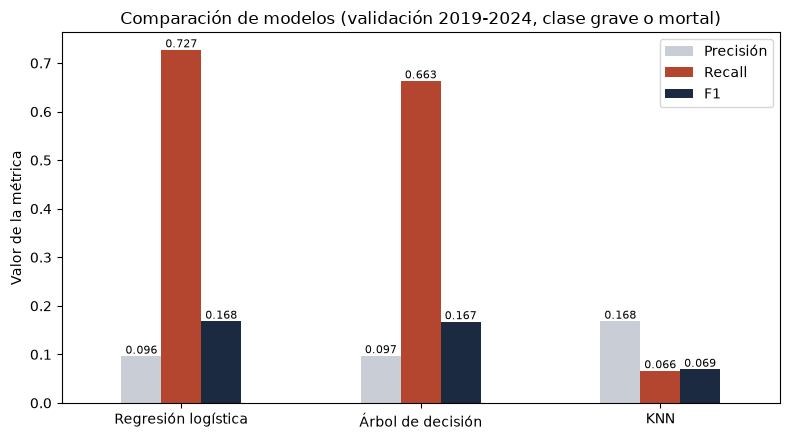

In [10]:
# Gráfico de la comparación (mismos valores de la tabla anterior)
tabla_comp = pd.DataFrame(comparacion).set_index("modelo")[["precision", "recall", "f1"]]

ax = tabla_comp.plot(kind="bar", figsize=(8, 4.5), rot=0,
                     color=["#C9CED6", "#B4462F", "#1B2A41"])
ax.set_title("Comparación de modelos (validación 2019-2024, clase grave o mortal)")
ax.set_xlabel("")
ax.set_ylabel("Valor de la métrica")
ax.legend(["Precisión", "Recall", "F1"])
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.3f", fontsize=8)
plt.tight_layout()
plt.savefig("../reports/figures/comparacion_modelos.png", dpi=150)
plt.show()

**Elección:** se elige la regresión logística (C = 1). Su F1 en la validación es prácticamente igual al del árbol (0,168 contra 0,167), pero detecta más siniestros graves (recall 0,727 contra 0,663), que es el error más costoso en este problema. Además, estima una probabilidad para cada siniestro, lo que permite ajustar el umbral de decisión, y sus coeficientes permiten ver qué factores se asocian más con la gravedad. KNN se descarta porque, sin una forma de compensar el desbalance, casi no detecta siniestros graves.

## 9. Elección del umbral

La regresión logística clasifica como grave cuando la probabilidad estimada supera 0,5, pero ese valor puede ajustarse: un umbral más bajo detecta más siniestros graves a costa de más falsas alarmas, y uno más alto, lo contrario. El umbral se elige con las predicciones de la validación temporal, sin usar el conjunto de prueba.

In [11]:
# Probabilidades de la validación temporal con el modelo elegido
prob_validacion, y_validacion = [], []
for idx_ent, idx_val in validacion.split(X_entrenamiento):
    modelo = clone(busqueda_logistica.best_estimator_)
    modelo.fit(X_entrenamiento.iloc[idx_ent], y_entrenamiento.iloc[idx_ent])
    prob_validacion.extend(modelo.predict_proba(X_entrenamiento.iloc[idx_val])[:, 1])
    y_validacion.extend(y_entrenamiento.iloc[idx_val])
prob_validacion, y_validacion = np.array(prob_validacion), np.array(y_validacion)

# Métricas para distintos umbrales
filas = []
for umbral in np.arange(0.30, 0.81, 0.05):
    pred = (prob_validacion >= umbral).astype(int)
    filas.append({
        "umbral": round(umbral, 2),
        "precision": round(precision_score(y_validacion, pred), 3),
        "recall": round(recall_score(y_validacion, pred), 3),
        "f1": round(f1_score(y_validacion, pred), 3),
        "alarmas": pred.sum(),
        "falsas_alarmas": ((pred == 1) & (y_validacion == 0)).sum()
    })
tabla_umbrales = pd.DataFrame(filas)
tabla_umbrales

,umbral,precision,recall,f1,alarmas,falsas_alarmas
0,0.30,0.078,0.919,0.143,28285,26092
1,0.35,0.081,0.886,0.148,26212,24099
2,0.40,0.084,0.848,0.153,24057,22033
3,0.45,0.088,0.795,0.159,21487,19590
4,0.50,0.094,0.731,0.166,18650,16906
5,0.55,0.100,0.663,0.174,15802,14220
6,0.60,0.107,0.584,0.180,13077,11683
7,0.65,0.111,0.495,0.181,10655,9474
8,0.70,0.116,0.420,0.182,8593,7592
9,0.75,0.117,0.344,0.175,7004,6183


In [12]:
# Umbral más alto que mantiene un recall de al menos 70% en la validación
umbral_elegido = tabla_umbrales.loc[tabla_umbrales["recall"] >= 0.70, "umbral"].max()
print("Umbral elegido:", umbral_elegido)

Umbral elegido: 0.5


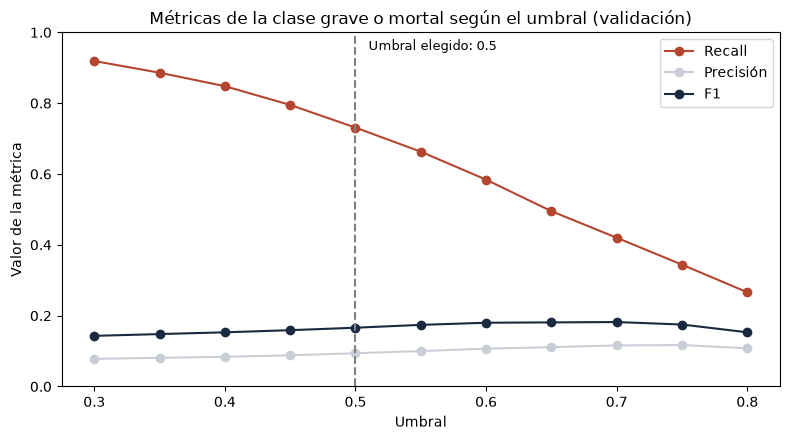

In [13]:
# Gráfico de recall, precisión y F1 según el umbral (validación)
ax = tabla_umbrales.plot(x="umbral", y=["recall", "precision", "f1"], marker="o",
                         figsize=(8, 4.5), color=["#B4462F", "#C9CED6", "#1B2A41"])
ax.axvline(umbral_elegido, color="gray", linestyle="--")
ax.text(umbral_elegido + 0.01, 0.95, f"Umbral elegido: {umbral_elegido}", fontsize=9)
ax.set_title("Métricas de la clase grave o mortal según el umbral (validación)")
ax.set_xlabel("Umbral")
ax.set_ylabel("Valor de la métrica")
ax.set_ylim(0, 1)
ax.legend(["Recall", "Precisión", "F1"])
plt.tight_layout()
plt.savefig("../reports/figures/umbral_validacion.png", dpi=150)
plt.show()

**Observaciones y elección del umbral:**

- Al bajar el umbral aumenta la detección de siniestros graves (recall), pero también la cantidad de falsas alarmas. Al subirlo pasa lo contrario. El F1 máximo (0,182) se alcanza con un umbral de 0,70, pero con ese valor el modelo no detectaría casi 6 de cada 10 siniestros graves.
- **Criterio del proyecto:** como no detectar un siniestro grave es el error más costoso, se elige el umbral más alto que mantiene un recall de al menos 70% en la validación. El valor de 70% es una decisión de este proyecto, no un estándar externo.
- Con ese criterio, el umbral elegido es 0,50: en la validación detecta el 73,1% de los siniestros graves, con una precisión de 9,4%.

## 10. Evaluación final con el conjunto de prueba (2025)

El modelo elegido (regresión logística, C = 1, umbral 0,50) se entrena con todo el período 2019-2024 y se evalúa una única vez con los siniestros de 2025, que no se usaron en ninguna decisión anterior del modelado. Después de esta evaluación no se modifican el modelo ni el umbral.

                precision    recall  f1-score   support

          Leve      0.956     0.640     0.767      9398
Grave o mortal      0.123     0.634     0.206       751

      accuracy                          0.639     10149
     macro avg      0.540     0.637     0.487     10149
  weighted avg      0.895     0.639     0.725     10149

Alarmas: 3860 | Falsas alarmas: 3384


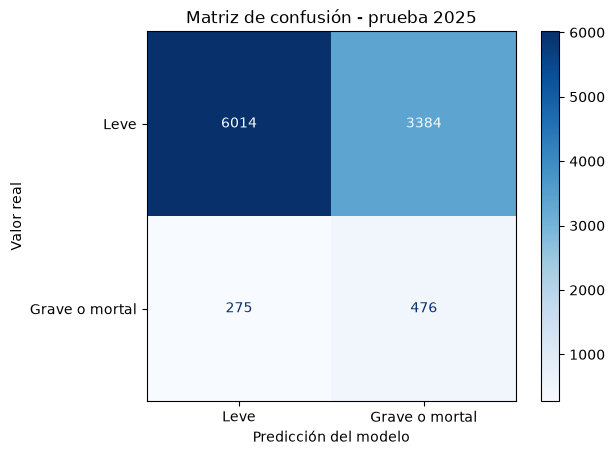

In [14]:
# GridSearchCV ya reentrenó la mejor configuración con todo el entrenamiento (refit)
modelo_final = busqueda_logistica.best_estimator_

prob_prueba = modelo_final.predict_proba(X_prueba)[:, 1]
pred_prueba = (prob_prueba >= umbral_elegido).astype(int)

print(classification_report(y_prueba, pred_prueba, digits=3,
                            target_names=["Leve", "Grave o mortal"]))
print("Alarmas:", pred_prueba.sum(),
      "| Falsas alarmas:", ((pred_prueba == 1) & (y_prueba == 0)).sum())

ConfusionMatrixDisplay.from_predictions(y_prueba, pred_prueba,
                                        display_labels=["Leve", "Grave o mortal"],
                                        cmap="Blues")
plt.title("Matriz de confusión - prueba 2025")
plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")
plt.savefig("../reports/figures/matriz_confusion_2025.png", dpi=200, bbox_inches="tight")
plt.show()

**Observaciones:**

- En 2025, el modelo detecta 476 de los 751 siniestros graves o mortales (recall 0,634), con una precisión de 0,123 y un F1 de 0,206 para esa clase.
- El recall es menor que en la validación (0,731), por lo que en 2025 no se alcanza el 70% buscado. El modelo y el umbral no se modifican después de esta evaluación: el resultado se informa tal como se obtuvo.
- La precisión de 12,3% significa que aproximadamente 1 de cada 8 alarmas corresponde a un siniestro grave. Como en 2025 el 7,4% de los siniestros fue grave, una selección al azar acertaría 1 de cada 13,5: el modelo concentra los casos graves alrededor de 1,7 veces más que el azar.
- El costo es alto: el modelo marca como posibles graves 3.860 siniestros (38% del total), de los cuales 3.384 son falsas alarmas. La exactitud (0,639) es menor que la de un modelo que siempre predice "leve" (0,926), pero ese modelo no detectaría ningún caso grave.
- En conjunto, con las variables disponibles al aviso, el modelo ordena el riesgo mejor que el azar pero con una capacidad limitada: puede servir como apoyo para priorizar, no como una clasificación confiable por sí sola.

## 11. Interpretación del modelo: qué factores pesan más

La regresión logística asigna un coeficiente a cada categoría. Un coeficiente positivo aumenta la probabilidad estimada de que el siniestro sea grave, y uno negativo la disminuye. Cuanto más lejos de cero, mayor es su peso en el modelo.

Estos coeficientes muestran asociaciones aprendidas de los datos, no causas: indican qué características acompañan con más frecuencia a los siniestros graves, no que las produzcan.

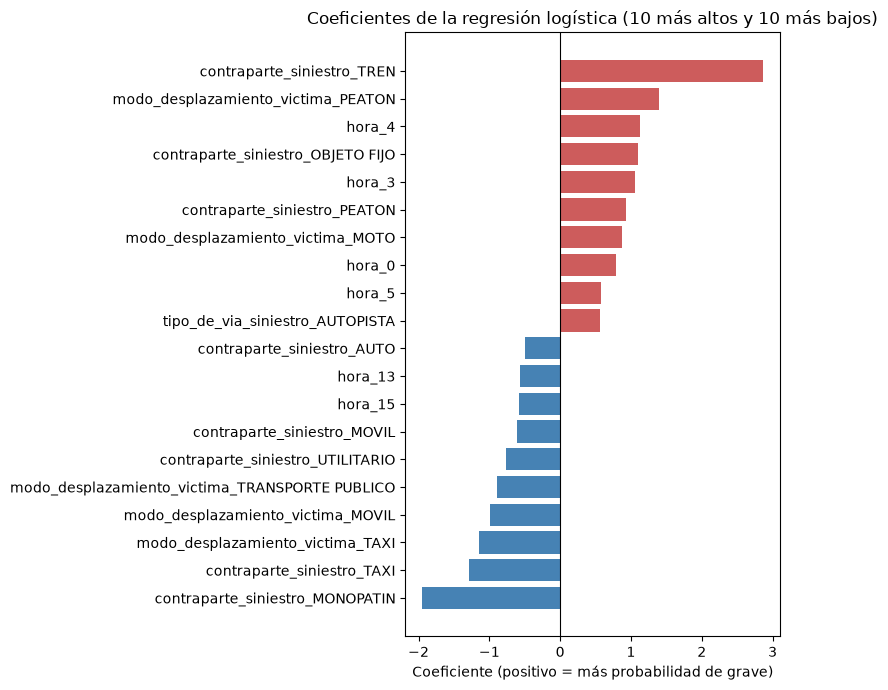

In [15]:
# Nombres de las columnas después de la codificación y sus coeficientes
nombres = modelo_final.named_steps["preprocesamiento"].get_feature_names_out()
coeficientes = modelo_final.named_steps["modelo"].coef_[0]

tabla_coef = pd.DataFrame({
    "variable": [n.split("__")[1] for n in nombres],   # saco el prefijo "categoricas__"
    "coeficiente": coeficientes.round(3)
}).sort_values("coeficiente")

# Las 10 que más aumentan y las 10 que más disminuyen la probabilidad de grave
extremos = pd.concat([tabla_coef.head(10), tabla_coef.tail(10)])

plt.figure(figsize=(8, 7))
colores = ["steelblue" if c < 0 else "indianred" for c in extremos["coeficiente"]]
plt.barh(extremos["variable"], extremos["coeficiente"], color=colores)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Coeficientes de la regresión logística (10 más altos y 10 más bajos)")
plt.xlabel("Coeficiente (positivo = más probabilidad de grave)")
plt.tight_layout()
plt.savefig("../reports/figures/coeficientes.png", dpi=200, bbox_inches="tight")
plt.show()

**Observaciones:**

- Las características más asociadas a siniestros graves son la contraparte tren, la víctima peatón, las horas de madrugada (0, 3, 4 y 5), el choque contra un objeto fijo, el atropello de un peatón como contraparte, la víctima en moto y la autopista. Coinciden con lo observado en el análisis exploratorio.
- Las más asociadas a siniestros leves son las víctimas o contrapartes en taxi, transporte público, móvil o utilitario, la contraparte auto y las horas de la tarde.
- La lluvia, el tipo de día y la estación no aparecen entre los 20 coeficientes más extremos, por lo que tienen poco peso en el modelo.
- Algunas categorías, como tren o monopatín, tienen muy pocos casos, por lo que sus coeficientes son poco estables y deben interpretarse con cautela.
- Son asociaciones, no causas: por ejemplo, que la madrugada tenga más peso no permite afirmar por qué ocurre (podría relacionarse con la velocidad, la visibilidad u otros factores no registrados).

## 12. Uso del modelo con casos nuevos (ejemplo sintético)

Para mostrar cómo se usa el modelo, se crean dos siniestros **ficticios**: no pertenecen al dataset y se inventaron solo para esta demostración. Para cada uno se cargan las mismas siete predictoras disponibles al recibir el aviso. El modelo aplica la misma codificación y escalado aprendidos del entrenamiento, calcula la probabilidad de que el siniestro sea grave o mortal y la compara con el umbral de 0,50.

Esta demostración muestra el funcionamiento del modelo, no su desempeño: el desempeño es el que se midió con el conjunto de prueba.

In [16]:
# Dos siniestros ficticios (datos inventados para la demostración)
casos_nuevos = pd.DataFrame([
    {"modo_desplazamiento_victima": "MOTO", "contraparte_siniestro": "OBJETO FIJO",
     "tipo_de_via_siniestro": "AUTOPISTA", "tipo_dia": "FIN DE SEMANA",
     "estacion": "INVIERNO", "hora": 4, "lluvia_mm": 0.0},
    {"modo_desplazamiento_victima": "TRANSPORTE PUBLICO", "contraparte_siniestro": "AUTO",
     "tipo_de_via_siniestro": "CALLE", "tipo_dia": "HABIL",
     "estacion": "PRIMAVERA", "hora": 15, "lluvia_mm": 0.0}
])

# Probabilidad de grave o mortal y clasificación con el umbral elegido
casos_nuevos["probabilidad_grave"] = modelo_final.predict_proba(casos_nuevos[categoricas + numericas])[:, 1].round(3)
casos_nuevos["prediccion"] = np.where(casos_nuevos["probabilidad_grave"] >= umbral_elegido,
                                      "Grave o mortal", "Leve")
casos_nuevos

,modo_desplazamiento_victima,contraparte_siniestro,tipo_de_via_siniestro,tipo_dia,estacion,hora,lluvia_mm,probabilidad_grave,prediccion
0,MOTO,OBJETO FIJO,AUTOPISTA,FIN DE SEMANA,INVIERNO,4,0.0,0.976,Grave o mortal
1,TRANSPORTE PUBLICO,AUTO,CALLE,HABIL,PRIMAVERA,15,0.0,0.077,Leve


**Observaciones:**

- El primer caso ficticio (víctima en moto contra un objeto fijo, en autopista, fin de semana, a las 4 de la madrugada) obtiene un valor de 0,976 y se clasifica como grave o mortal. El segundo (víctima en transporte público contra un auto, en una calle, día hábil, a las 15) obtiene 0,077 y se clasifica como leve.
- Como el modelo se entrenó con `class_weight="balanced"`, estos valores no deben leerse como probabilidades reales (por ejemplo, 0,976 no significa un 97,6% de chances de que sea grave): el balanceo los desplaza hacia arriba para detectar más casos graves. Sirven para ordenar los siniestros según su riesgo relativo y compararlos con el umbral.
- Los casos son inventados: muestran cómo se usa el modelo, no prueban que acierte.

## 13. Guardado del modelo

Se guarda el modelo final (preprocesamiento + regresión logística, entrenado con 2019-2024) junto con el umbral elegido en `models/modelo_gravedad_siniestros.joblib`. Así puede reutilizarse para clasificar casos nuevos sin volver a entrenarlo.

In [17]:
# Guardo el modelo y el umbral juntos en un solo archivo
joblib.dump({"modelo": modelo_final, "umbral": umbral_elegido},
            "../models/modelo_gravedad_siniestros.joblib")

# Verifico que se puede cargar y usar
cargado = joblib.load("../models/modelo_gravedad_siniestros.joblib")
print("Umbral guardado:", cargado["umbral"])
print("Probabilidades de los casos ficticios:",
      cargado["modelo"].predict_proba(casos_nuevos[categoricas + numericas])[:, 1].round(3))

Umbral guardado: 0.5
Probabilidades de los casos ficticios: [0.976 0.077]


**Observaciones:** el modelo se guardó y se cargó correctamente: el umbral es 0,5 y las probabilidades de los casos ficticios coinciden con las calculadas antes (0,976 y 0,077).

## 14. Conclusiones

**Respuesta a la pregunta del proyecto.** Con la información disponible al aviso (vehículo de la víctima, contraparte, tipo de vía, hora, lluvia, tipo de día y estación), es posible anticipar en parte si un siniestro será grave o mortal, pero con una capacidad limitada. En 2025, el modelo detectó el 63,4% de los siniestros graves y aproximadamente 1 de cada 8 de sus alarmas fue correcta, cerca de 1,7 veces más que una selección al azar. Puede servir como apoyo para priorizar la respuesta, no como una clasificación confiable por sí sola.

**Modelo elegido.** De los tres modelos planteados en la propuesta inicial, la regresión logística y el árbol de decisión obtuvieron resultados similares en la validación, y KNN no fue adecuado por el desbalance de clases. Se eligió la regresión logística porque detectó más siniestros graves, estima una probabilidad que permite ajustar el umbral y sus coeficientes son interpretables.

**Factores asociados a la gravedad.** Los siniestros con peatones, motos, objetos fijos o trenes, en autopista y durante la madrugada se asocian con mayor gravedad. Son asociaciones observadas en los datos, no causas demostradas.

**Cambios respecto de la propuesta inicial.**
- La partición pasó de estratificada aleatoria a temporal (entrenamiento 2019-2024, prueba 2025), para simular el uso real y evitar mezclar períodos.
- La comuna se excluyó como predictora, porque aportó poca información y sus faltantes podrían depender de cómo se completa el registro.

**Limitaciones.**
- El modelo solo aplica a siniestros con el vehículo de la víctima y la contraparte informados (se excluyó el 22,3% de los registros).
- La lluvia es un dato retrospectivo de un único punto de la Ciudad, no disponible en tiempo real.
- No es posible verificar si cada dato se registró al momento del aviso o se completó después.
- El análisis exploratorio usó todo el período, incluido 2025.
- Faltan variables relevantes que el dataset no registra, como la velocidad, el uso de casco o cinturón y el alcohol.
- Los resultados corresponden a CABA. Aplicarlos en otra jurisdicción requeriría datos locales y reentrenar el modelo.

**Trabajo futuro.** Incorporar variables disponibles en tiempo real (por ejemplo, una estación meteorológica), sumar información de la ubicación, probar modelos que capten combinaciones de factores y reentrenar con años posteriores.